# STAR Project – Class Type Effects Over Time

**Goal:** For each grade (K to 8), estimate the effect of class type on math scores, with 95% confidence intervals.
Does the effect fade to zero after the experiment ends (after grade 3)?

**Three binary comparisons:**
1. Small vs Regular
2. Small vs Regular + Aide
3. Regular + Aide vs Regular

## 1. Load data and set up

Each student gets their **first** class type (the class type they were assigned when they entered the study).
This follows the original random assignment, even if the student later switched.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_spss("../data/raw/STAR_Students.sav")
df = df.copy()

grades = ["gk", "g1", "g2", "g3", "g4", "g5", "g6", "g7", "g8"]
k3 = ["gk", "g1", "g2", "g3"]

classtype_cols = [f"{g}classtype" for g in k3]
df["first_classtype"] = df[classtype_cols].astype(object).bfill(axis=1).iloc[:, 0]
df["first_classtype"].value_counts()

first_classtype
REGULAR CLASS           4328
REGULAR + AIDE CLASS    4249
SMALL CLASS             3024
Name: count, dtype: int64

## 2. Compute the effects

**Why standardize?** K–3 and 4–8 used different tests, so raw points can't be compared across grades.
In each grade we turn scores into z-scores (mean 0, SD 1). The effect is then in **standard deviations**.

For each grade and each comparison:
- **effect** = mean z of group A − mean z of group B
- **95% CI** = effect ± 1.96 × standard error
- **p-value** from a two-sided test (we keep it for the multiple-comparison correction later)

Note: this simple version does not control for school yet.

In [2]:
comparisons = [
    ("SMALL CLASS", "REGULAR CLASS", "Small vs Regular"),
    ("SMALL CLASS", "REGULAR + AIDE CLASS", "Small vs Regular+Aide"),
    ("REGULAR + AIDE CLASS", "REGULAR CLASS", "Regular+Aide vs Regular"),
]

rows = []
for g in grades:
    score = df[f"{g}tmathss"]
    z = (score - score.mean()) / score.std()   # standardize within grade

    for a, b, label in comparisons:
        za = z[df["first_classtype"] == a].dropna()
        zb = z[df["first_classtype"] == b].dropna()

        effect = za.mean() - zb.mean()
        se = np.sqrt(za.var() / len(za) + zb.var() / len(zb))
        p = 2 * stats.norm.sf(abs(effect / se))

        rows.append({
            "grade": g, "comparison": label,
            "effect": effect, "ci_low": effect - 1.96 * se, "ci_high": effect + 1.96 * se,
            "p_value": p, "n_a": len(za), "n_b": len(zb),
        })

results = pd.DataFrame(rows)
results.round(3)

,grade,comparison,effect,ci_low,ci_high,p_value,n_a,n_b
0,gk,Small vs Regular,0.162,0.097,0.227,0.000,1762,2032
1,gk,Small vs Regular+Aide,0.171,0.107,0.234,0.000,1762,2077
2,gk,Regular+Aide vs Regular,-0.008,-0.068,0.051,0.782,2077,2032
3,g1,Small vs Regular,0.273,0.211,0.335,0.000,1728,2471
4,g1,Small vs Regular+Aide,0.223,0.161,0.286,0.000,1728,2399
5,g1,Regular+Aide vs Regular,0.050,-0.005,0.105,0.076,2399,2471
6,g2,Small vs Regular,0.184,0.119,0.249,0.000,1541,2295
7,g2,Small vs Regular+Aide,0.203,0.137,0.268,0.000,1541,2229
8,g2,Regular+Aide vs Regular,-0.019,-0.076,0.039,0.522,2229,2295
9,g3,Small vs Regular,0.161,0.098,0.225,0.000,1593,2247


## 3. The graphs

One graph per comparison, all with the same y-axis so they are easy to compare.
Error bars are 95% confidence intervals. The shaded area is the experiment years (K–3). The dashed line is zero (no effect).
If a confidence interval crosses zero, the effect in that grade is not significant.

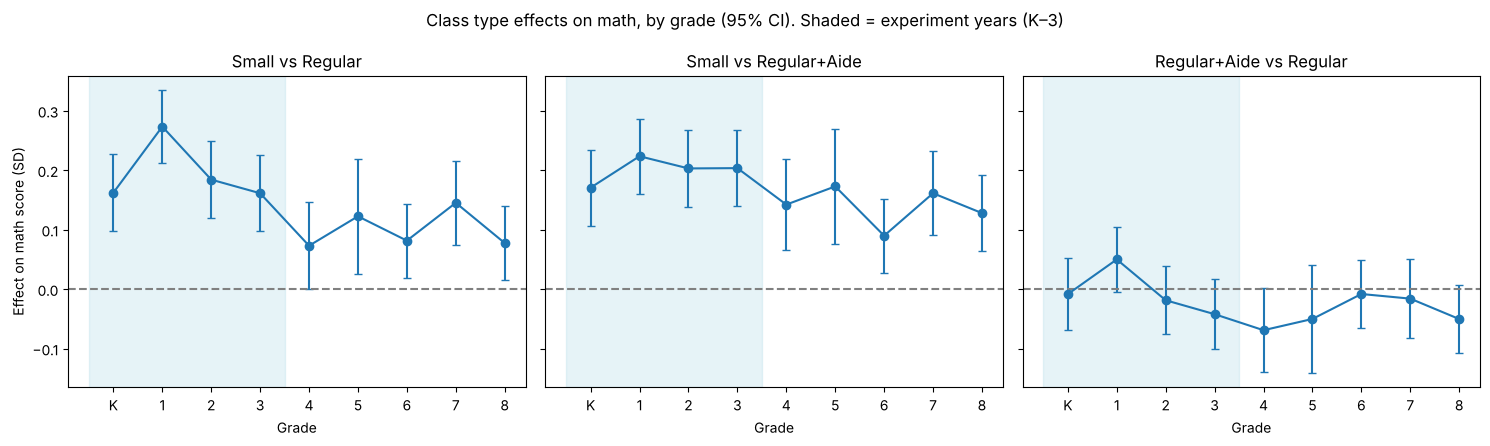

In [3]:
grade_labels = ["K", "1", "2", "3", "4", "5", "6", "7", "8"]
x = np.arange(len(grades))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, (a, b, label) in zip(axes, comparisons):
    r = results[results["comparison"] == label]
    ax.errorbar(x, r["effect"],
                yerr=[r["effect"] - r["ci_low"], r["ci_high"] - r["effect"]],
                marker="o", capsize=3)
    ax.axhline(0, color="gray", linestyle="--")
    ax.axvspan(-0.5, 3.5, color="lightblue", alpha=0.3)
    ax.set_xticks(x)
    ax.set_xticklabels(grade_labels)
    ax.set_xlabel("Grade")
    ax.set_title(label)

axes[0].set_ylabel("Effect on math score (SD)")
fig.suptitle("Class type effects on math, by grade (95% CI). Shaded = experiment years (K–3)")
plt.tight_layout()
plt.savefig("../figures/class_type_effects.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Summary table

Effect per grade for each comparison (in SD), with the 95% CI in brackets.
`*` = the 95% CI does not include zero.

In [4]:
def fmt(v):
    return f"{round(v, 2) + 0:.2f}"   # 2 decimals, and no "-0.00"

results["label"] = (results["effect"].map(fmt)
                    + " [" + results["ci_low"].map(fmt) + ", " + results["ci_high"].map(fmt) + "]"
                    + np.where(results["p_value"] < 0.05, "*", ""))

table = results.pivot(index="grade", columns="comparison", values="label").loc[grades]
table = table[[label for a, b, label in comparisons]]   # same order as the graphs
table.index = grade_labels
table.index.name = "Grade"
table.columns.name = None
table

,Small vs Regular,Small vs Regular+Aide,Regular+Aide vs Regular
Grade,,,
K,"0.16 [0.10, 0.23]*","0.17 [0.11, 0.23]*","-0.01 [-0.07, 0.05]"
1,"0.27 [0.21, 0.34]*","0.22 [0.16, 0.29]*","0.05 [-0.01, 0.10]"
2,"0.18 [0.12, 0.25]*","0.20 [0.14, 0.27]*","-0.02 [-0.08, 0.04]"
3,"0.16 [0.10, 0.22]*","0.20 [0.14, 0.27]*","-0.04 [-0.10, 0.02]"
4,"0.07 [0.00, 0.15]","0.14 [0.07, 0.22]*","-0.07 [-0.14, 0.00]"
5,"0.12 [0.03, 0.22]*","0.17 [0.08, 0.27]*","-0.05 [-0.14, 0.04]"
6,"0.08 [0.02, 0.14]*","0.09 [0.03, 0.15]*","-0.01 [-0.07, 0.05]"
7,"0.15 [0.07, 0.22]*","0.16 [0.09, 0.23]*","-0.02 [-0.08, 0.05]"
8,"0.08 [0.01, 0.14]*","0.13 [0.06, 0.19]*","-0.05 [-0.11, 0.01]"


## Notes

_What do we see? Where does each effect cross zero?_

**Next step:** correct the p-values for multiple comparisons (3 comparisons × 9 grades = 27 tests).